# Interpretable Deep Learning for Single-Cell RNA-seq Classification
## Project objective
- Investigating whether machine-learning models can classify immune cell types from single-cell RNA sequencing (scRNA-seq) data while generalising across experimental batches.
- A Logistic Regression model will be used as a baseline and compared with a feed-forward neural network implemented in PyTorch.
- The neural network will be interpreted using Integrated Gradients to investigate which genes contribute most strongly to individual cell-type predictions.
## Research questions
1. Can cell types be classified accurately from single-cell gene-expression profiles?
2. Does a neural network improve upon a strong classical machine-learning baseline?
3. Do the models generalise to cells from a different experimental batch?
4. Are the neural network's predictions driven by biologically meaningful gene features?

In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import torch
from importlib.metadata import version

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Scanpy:", version("scanpy"))
print("scvi-tools:", version("scvi-tools"))

PyTorch: 2.14.0+cpu
Scanpy: 1.11.5
scvi-tools: 1.4.2


## Dataset Information
The analysis uses a publicly available single-cell RNA-seq dataset containing peripheral blood mononuclear cells (PBMCs).

In the expression matrix:
- each row represents an individual cell
- each column represents a gene
- each value represents the measured expression of that gene in that cell

In [2]:
adata = scvi.data.pbmc_dataset()
adata

INFO     File data/gene_info_pbmc.csv already downloaded                                                           
INFO     File data/pbmc_metadata.pickle already downloaded                                                         
INFO     File data/pbmc8k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc8k/filtered_gene_bc_matrices                                          
INFO     File data/pbmc4k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc4k/filtered_gene_bc_matrices                                          


/home/fionnualamoody/projects/single-cell-interpretable-ml/.venv/lib/python3.11/site-packages/scvi/data/_built_in_data/_pbmc.py:75: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = pbmc8k.concatenate(pbmc4k)


AnnData object with n_obs × n_vars = 11990 × 3346
    obs: 'n_counts', 'batch', 'labels', 'str_labels'
    var: 'gene_symbols', 'n_counts-0', 'n_counts-1', 'n_counts'
    uns: 'cell_types'
    obsm: 'design', 'raw_qc', 'normalized_qc', 'qc_pc'

## Initial data exploration
Before preprocessing or modelling, the structure of the dataset is examined to assess class imbalance and inform the train/validation/test strategy

In [3]:
print("Dataset shape:", adata.shape)
print("\nCell metadata:")
display(adata.obs.head())
print("\nGene metadata:")
display(adata.var.head())

Dataset shape: (11990, 3346)

Cell metadata:


,n_counts,batch,labels,str_labels
AAACCTGAGCTAGTGG-1,4520.0,0,2,CD4 T cells
AAACCTGCACATTAGC-1,2788.0,0,2,CD4 T cells
AAACCTGCACTGTTAG-1,4667.0,0,1,CD14+ Monocytes
AAACCTGCATAGTAAG-1,4440.0,0,1,CD14+ Monocytes
AAACCTGCATGAACCT-1,3224.0,0,3,CD8 T cells



Gene metadata:


,gene_symbols,n_counts-0,n_counts-1,n_counts
ENSG00000188976,NOC2L,1477.0,718.0,2135.0
ENSG00000187608,ISG15,4014.0,1888.0,5705.0
ENSG00000149527,PLCH2,121.0,41.0,157.0
ENSG00000157881,PANK4,224.0,107.0,326.0
ENSG00000157873,TNFRSF14,3639.0,1683.0,5193.0


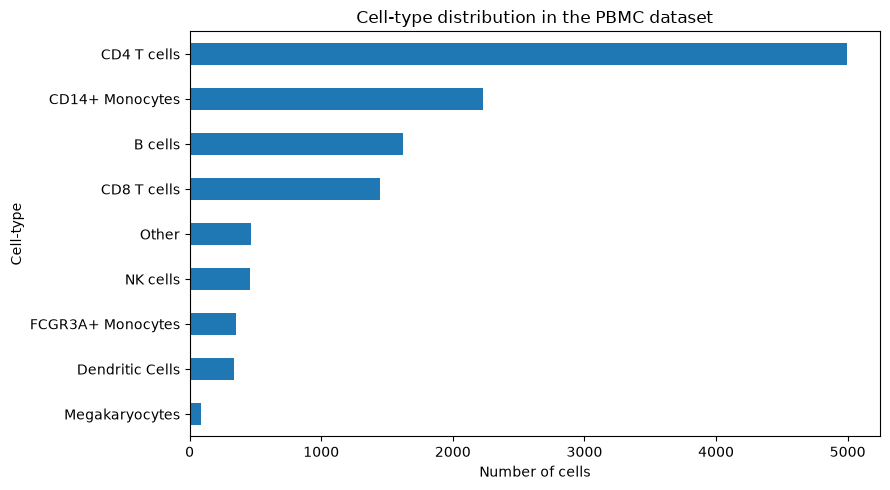

In [4]:
# Look at cell-types
cell_counts= (
    adata.obs["str_labels"]
    .value_counts()
    .sort_values(ascending=False)
)
cell_counts
plt.figure(figsize=(9,5))
cell_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of cells")
plt.ylabel("Cell-type")
plt.title("Cell-type distribution in the PBMC dataset")
plt.tight_layout()
plt.show()

In [5]:
# Exploring the batches
print("Cells per batch:")
display(adata.obs["batch"].value_counts())
print("\nCell-types by batch:")

batch_table = pd.crosstab(
    adata.obs["str_labels"],
    adata.obs["batch"]
)
display(batch_table)

Cells per batch:


batch
0    7982
1    4008
Name: count, dtype: int64


Cell-types by batch:


batch,0,1
str_labels,,
B cells,1060,561
CD14+ Monocytes,1483,744
CD4 T cells,3364,1632
CD8 T cells,948,500
Dendritic Cells,209,130
FCGR3A+ Monocytes,224,127
Megakaryocytes,63,25
NK cells,285,172
Other,346,117


## Experimental design
- Batch 1 will be retained as the held-out test set.
- Batch 0 will be divided into training and validation subsets.


In [6]:
from sklearn.model_selection import train_test_split

batch_values = adata.obs["batch"].astype(str)

batch0_names = adata.obs_names[batch_values == "0"]
batch1_names = adata.obs_names[batch_values == "1"]

batch0_labels = adata.obs.loc[batch0_names, "str_labels"]

# using stratify so that the train and val subsets keep around  the same class proportions
train_names, val_names = train_test_split(
    batch0_names,
    test_size = 0.20,
    random_state = SEED,
    stratify = batch0_labels
)

test_names = batch1_names

train = adata[train_names].copy()
val = adata[val_names].copy()
test = adata[test_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)


## Preprocessing
- Preprocessing is performed using the training data where possible to minimise information leakage. Gene filtering and highly variable gene selection are then applied consistently to the validation and test sets.

In [7]:
from scipy.sparse import issparse

X_sample = train.X[:10, :10]

if issparse(X_sample):
    X_sample = X_sample.toarray()

print(X_sample)
print("\nMinimum:", X_sample.min())
print("Maximum:", X_sample.max())

# testing larger section of matrix
X_check = train.X[:100, :100]

if issparse(X_check):
    X_check = X_check.toarray()

print(
    "All sampled values integer-like:",
    np.allclose(X_check, np.round(X_check))
)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Minimum: 0.0
Maximum: 2.0
All sampled values integer-like: True


## Gene filtering and normalisation

- Genes detected in very few cells are removed because they provide limited information for classification and may add noise.
- Expression values are normalised per cell to reduce differences in sequencing depth. A log transformation is applied to compress the highly skewed distribution of gene-expression values.
  

In [8]:
#  Filter genes using just the training set
sc.pp.filter_genes(train, min_cells=3)

genes_kept = train.var_names.copy()

# Apply same gene set to the validation and test data
val = val[:, genes_kept].copy()
test = test[:, genes_kept].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

for dataset in [train, val, test]:
    sc.pp.normalize_total(dataset, target_sum=1e4)
    sc.pp.log1p(dataset)

print("Genes after filtering:", train.n_vars)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)
Genes after filtering: 3346


## Highly variable gene selection
- Single-cell datasets contain many genes whose expression varies little across cells or contributes limited information for distinguishing cell populations.
- Next the 1,000 most highly variable genes are selected using the training data only. The same gene set is applied to the validation and test datasets.


In [9]:
sc.pp.highly_variable_genes(
    train,
    n_top_genes=1000,
    flavor="seurat",
    subset=False
)

hvg_names = train.var_names[train.var["highly_variable"]]

train = train[:, hvg_names].copy()
val = val[:, hvg_names].copy()
test = test[:, hvg_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 1000)
Validation set: (1597, 1000)
Test set: (4008, 1000)


## Preparing data for machine learning 

- The preprocessed AnnData expression matrices are converted into NumPy arrays for use with scikit-learn and PyTorch.
- Cell-type labels are encoded numerically and gene-expression features are standardised using statistics learned from the training set only.

In [10]:
from scipy.sparse import issparse

def to_dense_array(adata_object):
    X= adata_object.X

    if issparse(X):
        X = X.toarray()

    return np.asarray(X, dtype=np.float32)

X_train = to_dense_array(train)
X_val = to_dense_array(val)
X_test = to_dense_array(test)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (6385, 1000)
X_val: (1597, 1000)
X_test: (4008, 1000)


In [11]:
# Encode cell-type labels

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train.obs["str_labels"])
y_val = label_encoder.transform(val.obs["str_labels"])
y_test = label_encoder.transform(test.obs["str_labels"])

label_mapping = pd.DataFrame({
    "Encoded label": range(len(label_encoder.classes_)),
    "Cell-type": label_encoder.classes_
})

display(label_mapping)

,Encoded label,Cell-type
0,0,B cells
1,1,CD14+ Monocytes
2,2,CD4 T cells
3,3,CD8 T cells
4,4,Dendritic Cells
5,5,FCGR3A+ Monocytes
6,6,Megakaryocytes
7,7,NK cells
8,8,Other


## Standardise the gene features

- Gene-expression features are standardised to reduce differences in numerical scale between genes.
- The scaler is fitted using the training data only. The training means and standard deviations are applied to the validation and test sets to prevent information leakage. 

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

Training mean: -1.7780014e-09
Training standard deviation: 1.0


In [13]:
# Quick check
print("Feature matrices:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nLabel vectors:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

print("\nNumber of classes:", len(label_encoder.classes_))

Feature matrices:
Train: (6385, 1000)
Validation: (1597, 1000)
Test: (4008, 1000)

Label vectors:
Train: (6385,)
Validation: (1597,)
Test: (4008,)

Number of classes: 9


## Logistic Regression 
- Using a logistic regression classifier as a baseline.
- LR can work well on high-dimensional gene-expression data and provides a useful benchmark to compare the neural network.
- Balanced class weights are used due to the cell-type classes being imbalanced.
- Performance will be evaluated using overall accuracy and macro-averaged F1-score.

In [14]:
#Train baseline model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report
)

baseline_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state= SEED
)

baseline_model.fit(X_train_scaled, y_train)

# evaluate on validation data
val_predictions = baseline_model.predict(X_val_scaled)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(
    y_val,
    val_predictions,
    average = "macro"
)

print("Validation results")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Macro F1: {val_macro_f1:.4f}")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names = label_encoder.classes_
    )
)

Validation results
Accuracy: 0.9668
Macro F1: 0.9182
                   precision    recall  f1-score   support

          B cells       0.99      1.00      1.00       212
  CD14+ Monocytes       0.97      0.98      0.97       297
      CD4 T cells       0.98      0.99      0.98       673
      CD8 T cells       0.95      0.93      0.94       190
  Dendritic Cells       0.95      0.93      0.94        42
FCGR3A+ Monocytes       0.93      0.93      0.93        45
   Megakaryocytes       0.88      0.58      0.70        12
         NK cells       0.93      0.95      0.94        57
            Other       0.92      0.81      0.86        69

         accuracy                           0.97      1597
        macro avg       0.94      0.90      0.92      1597
     weighted avg       0.97      0.97      0.97      1597



- Following the Logistic Regression baseline model, 96.68% validation accuracy was achieved as well as a macro-F1 score of 0.9182.
- Performance was strong across most cell-types, although performance was lower for rarer classes such as megakaryocytes.
- The difference between overall accuracy and macro-F1 shows the importance of class-specific evaluation in an imbalanced dataset.


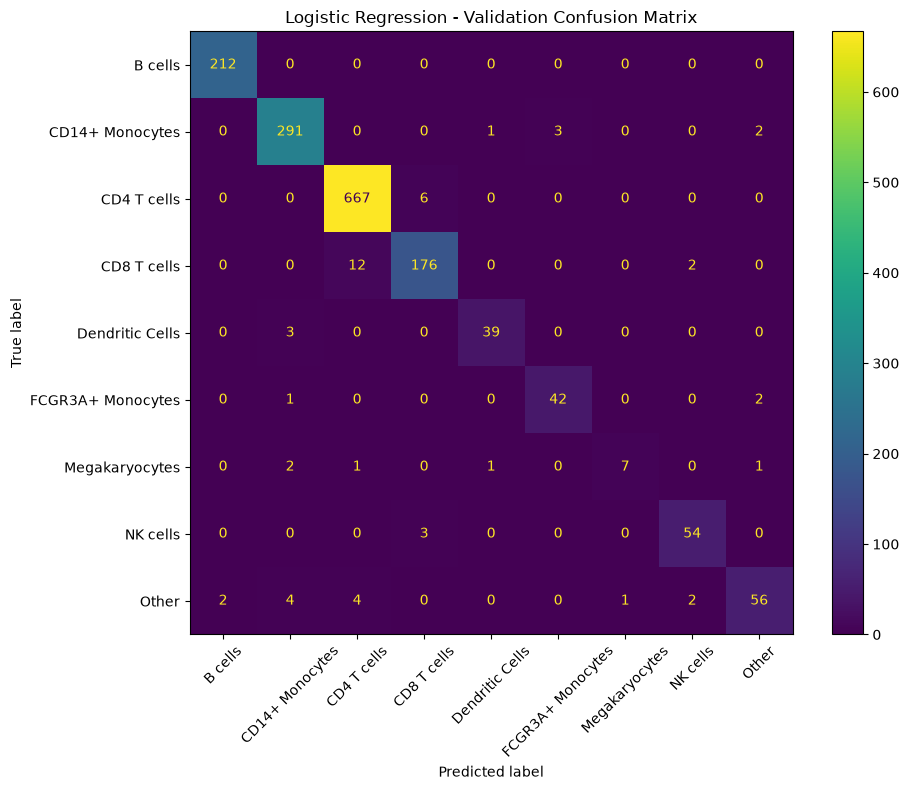

In [15]:
# Validation confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

- There is strong classification across the major cell populations.
- Most of the errors occurred between biologically related cell-types, especially CD4 and CD8 T cells, CD8 T cells and NK cells, and the two monocyte populations.
- Megakaryocytes had weaker performance, although the class contained only 12 validation cells.
- The "Other" category showed a broader pattern of misclassification.

In [16]:
# Evaluating LR on "Held-out" experimental batch
test_predictions = baseline_model.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, test_predictions)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("Held-out test results")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=label_encoder.classes_
    )
)

Held-out test results
Accuracy: 0.9618
Macro F1: 0.9391
                   precision    recall  f1-score   support

          B cells       0.98      0.98      0.98       561
  CD14+ Monocytes       0.95      0.98      0.96       744
      CD4 T cells       0.98      0.98      0.98      1632
      CD8 T cells       0.93      0.93      0.93       500
  Dendritic Cells       0.98      0.94      0.96       130
FCGR3A+ Monocytes       0.96      0.87      0.91       127
   Megakaryocytes       0.96      0.92      0.94        25
         NK cells       0.94      0.95      0.95       172
            Other       0.92      0.78      0.84       117

         accuracy                           0.96      4008
        macro avg       0.95      0.93      0.94      4008
     weighted avg       0.96      0.96      0.96      4008



- The LR model generalised well to the held-out batch as it achieved 96.18% accuracy and a macro-F1 score of 0.9391. Performance was close to the validation results despite the batch shift, however macro-F1 increased slightly.
- Most defined cell populations were classified with high F1 scores. Lower performance was observed for FCGR3A+ monocytes, CD8 T cells and the "Other" category. This suggests that the model captures cell-type-associated expression patterns that transfer across the two experimental batches represented in this dataset. 

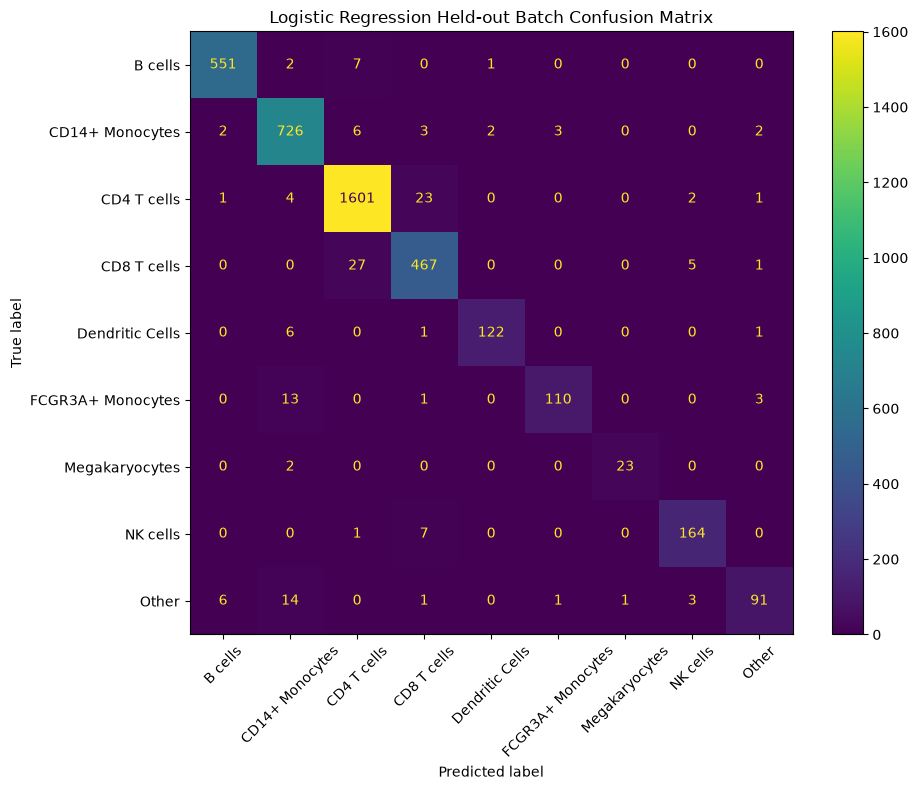

In [17]:
#  Held-out batch test confusion matrix
fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression Held-out Batch Confusion Matrix")
plt.tight_layout()
plt.show()

- The held-out confusion matrix above shows that most classification errors occurred between biologically related cell populations. The largest confusion was between CD4 and CD8 T cells, while some FCGR3A+ monocytes were classified as CD14+ monocytes. NK cells also showed limited confusion with CD8 T cells.
- The "Other" category showed the broadest spread of misclassifications. Major populations such as B cells, CD14+ monocytes and CD4 T cells were classified with high accuracy. Overall, the pattern of errors remained biologically plausible on the held-out experimental batch.

## Neural network classification with PyTorch

- A feed-forward neural network is trained to classify the nine cell types using the same 1,000 highly variable genes used by the Logistic Regression baseline.
- The model is trained on batch 0, with the validation subset used for model selection and early stopping, while batch 1 is reserved as the held-out test set.

In [18]:
# convert data into PyTorch tensors
import torch 
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor =torch.tensor(y_train, dtype=torch.long)
y_val_tensor =torch.tensor(y_val, dtype=torch.long)
y_test_tensor =torch.tensor(y_test, dtype=torch.long)

print("Training features:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)
print("Feature data type:", X_train_tensor.dtype)
print("Label data type:", y_train_tensor.dtype)

Training features: torch.Size([6385, 1000])
Training labels: torch.Size([6385])
Feature data type: torch.float32
Label data type: torch.int64


In [19]:
# create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset= TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 6385
Validation samples: 1597
Test samples: 4008


In [20]:
# create DataLoaders
train_loader =DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader =DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

test_loader =DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

X_batch, y_batch=next(iter(train_loader))

print("Feature batch:",X_batch.shape)
print("Label batch:",y_batch.shape)

Feature batch: torch.Size([128, 1000])
Label batch: torch.Size([128])


## Neural network architecture
- The neural network uses the 1,000 selected gene-expression features as input and predicts one of nine cell types.
- Two fully connected hidden layers are used, with ReLU activation and dropout regularisation to reduce overfitting.

In [21]:
# add model
import torch.nn as nn

class CellTypeMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.network=nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
    
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
    
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.network(x)
# create model
input_dim = X_train_scaled.shape[1]
num_classes =len(label_encoder.classes_)

model=CellTypeMLP(
    input_dim=input_dim,
    num_classes=num_classes
)

print(model)

CellTypeMLP(
  (network): Sequential(
    (0): Linear(in_features=1000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=9, bias=True)
  )
)


## Loss function and optimiser
- Because the cell-type classes are imbalanced, class weights are calculated from the training labels and incorporated into the loss function. This gives greater importance to errors made on rarer cell types.
- The model is optimised using AdamW with a learning rate of 1e-3 and weight decay of 1e-4.

In [22]:
# calculate class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights=compute_class_weight(
    class_weight ="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights=torch.tensor(
    class_weights,
    dtype=torch.float32
)

print(class_weights)

# create loss function and optimiser
loss_function=nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer=torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Number of classes:", num_classes)
print("Class weights:", class_weights)
print("Loss function:", loss_function)
print("Optimizer:", optimizer)

tensor([ 0.8366,  0.5982,  0.2636,  0.9359,  4.2482,  3.9634, 13.9107,  3.1116,
         2.5612])
Number of classes: 9
Class weights: tensor([ 0.8366,  0.5982,  0.2636,  0.9359,  4.2482,  3.9634, 13.9107,  3.1116,
         2.5612])
Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## Model training and early stopping
- The neural network is trained in mini-batches using the training subset. Performance is monitored on the validation set after each epoch using macro-averaged F1 score.
- Early stopping is used to retain the model state with the best validation macro-F1 score and to stop training when validation performance no longer improves.

In [23]:
from sklearn.metrics import f1_score
import copy

max_epochs=50
patience=8

best_val_f1=0.0
best_model_state= None
epochs_without_improvement = 0

training_losses =[]
validation_f1_scores=[]

for epoch in range(max_epochs):
    # train 
    model.train()
    running_loss=0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs=model(X_batch)
        loss=loss_function(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)

    epoch_loss=running_loss/len(train_loader.dataset)
    training_losses.append(epoch_loss)

    # Validation
    model.eval()

    val_predictions_nn = []
    val_targets_nn = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            predictions = torch.argmax(outputs, dim=1)

            val_predictions_nn.extend(predictions.cpu().numpy())
            val_targets_nn.extend(y_batch.cpu().numpy())

    val_f1 = f1_score(
        val_targets_nn,
        val_predictions_nn,
        average="macro"
    )

    validation_f1_scores.append(val_f1)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Validation Macro F1: {val_f1:.4f}"
    )

    # Early stopping
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best-performing model
model.load_state_dict(best_model_state)

print(f"\nBest validation Macro F1: {best_val_f1:.4f}")

Epoch 01 | Loss: 1.0302 | Validation Macro F1: 0.8882
Epoch 02 | Loss: 0.1418 | Validation Macro F1: 0.9267
Epoch 03 | Loss: 0.0589 | Validation Macro F1: 0.9312
Epoch 04 | Loss: 0.0322 | Validation Macro F1: 0.9210
Epoch 05 | Loss: 0.0204 | Validation Macro F1: 0.9344
Epoch 06 | Loss: 0.0133 | Validation Macro F1: 0.9356
Epoch 07 | Loss: 0.0092 | Validation Macro F1: 0.9392
Epoch 08 | Loss: 0.0070 | Validation Macro F1: 0.9327
Epoch 09 | Loss: 0.0047 | Validation Macro F1: 0.9335
Epoch 10 | Loss: 0.0045 | Validation Macro F1: 0.9390
Epoch 11 | Loss: 0.0050 | Validation Macro F1: 0.9443
Epoch 12 | Loss: 0.0048 | Validation Macro F1: 0.9247
Epoch 13 | Loss: 0.0027 | Validation Macro F1: 0.9286
Epoch 14 | Loss: 0.0029 | Validation Macro F1: 0.9416
Epoch 15 | Loss: 0.0023 | Validation Macro F1: 0.9330
Epoch 16 | Loss: 0.0018 | Validation Macro F1: 0.9352
Epoch 17 | Loss: 0.0020 | Validation Macro F1: 0.9351
Epoch 18 | Loss: 0.0020 | Validation Macro F1: 0.9328
Epoch 19 | Loss: 0.0017 | Va

In [24]:
# calculate best epoch without retraining
best_epoch=np.argmax(validation_f1_scores)+1
print("Best epoch:",best_epoch)
print(f"Best validation Macro F1:{best_val_f1:.4f}")

Best epoch: 11
Best validation Macro F1:0.9443


- The NN reached its best validation macro-F1 score of 0.9443 at epoch 11, exceeding the LR baseline of 0.9182.
- Training loss continued to decrease after this point while validation performance plateaued and declined, which indicated increasing overfitting to the training data. Early stopping therefore retained the model parameters from the best-performing validation epoch.

In [25]:
# evaluate NN on held-out batch
model.eval()
test_predictions_nn=[]
test_targets_nn=[]

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        outputs=model(X_batch)
        predictions=torch.argmax(outputs, dim=1)

        test_predictions_nn.extend(predictions.cpu().numpy())
        test_targets_nn.extend(y_batch.cpu().numpy())

nn_test_accuracy=accuracy_score(
    test_targets_nn,
    test_predictions_nn
)

nn_test_macro_f1=f1_score(
    test_targets_nn,
    test_predictions_nn,
    average="macro"
)

print("Neural network held-out results")
print(f"Accuracy: {nn_test_accuracy:.4f}")
print(f"Macro F1: {nn_test_macro_f1:.4f}")

print(
    classification_report(
        test_targets_nn,
        test_predictions_nn,
        target_names=label_encoder.classes_
    )
)

Neural network held-out results
Accuracy: 0.9608
Macro F1: 0.9409
                   precision    recall  f1-score   support

          B cells       0.99      0.98      0.98       561
  CD14+ Monocytes       0.95      0.98      0.96       744
      CD4 T cells       0.98      0.98      0.98      1632
      CD8 T cells       0.91      0.94      0.92       500
  Dendritic Cells       0.98      0.94      0.96       130
FCGR3A+ Monocytes       0.97      0.85      0.91       127
   Megakaryocytes       0.96      0.92      0.94        25
         NK cells       0.95      0.96      0.95       172
            Other       0.94      0.80      0.87       117

         accuracy                           0.96      4008
        macro avg       0.96      0.93      0.94      4008
     weighted avg       0.96      0.96      0.96      4008



## NN held-out performance
- The neural network achieved 96.08% accuracy and a macro-F1 score of 0.9409 on the held-out experimental batch, compared with 96.18% accuracy and a macro-F1 score of 0.9391 for Logistic Regression.
- Overall performance was therefore very similar between the two models. Logistic Regression achieved marginally higher accuracy, while the neural network achieved marginally higher macro-F1, indicating slightly more balanced performance across cell types.
- The neural network improved performance for some harder-to-classify populations, particularly the heterogeneous "Other" category, although class-level gains were not consistent across all cell types.
- These results show that both models generalised strongly across the two experimental batches, with no meaningful overall predictive advantage for the more complex neural network.

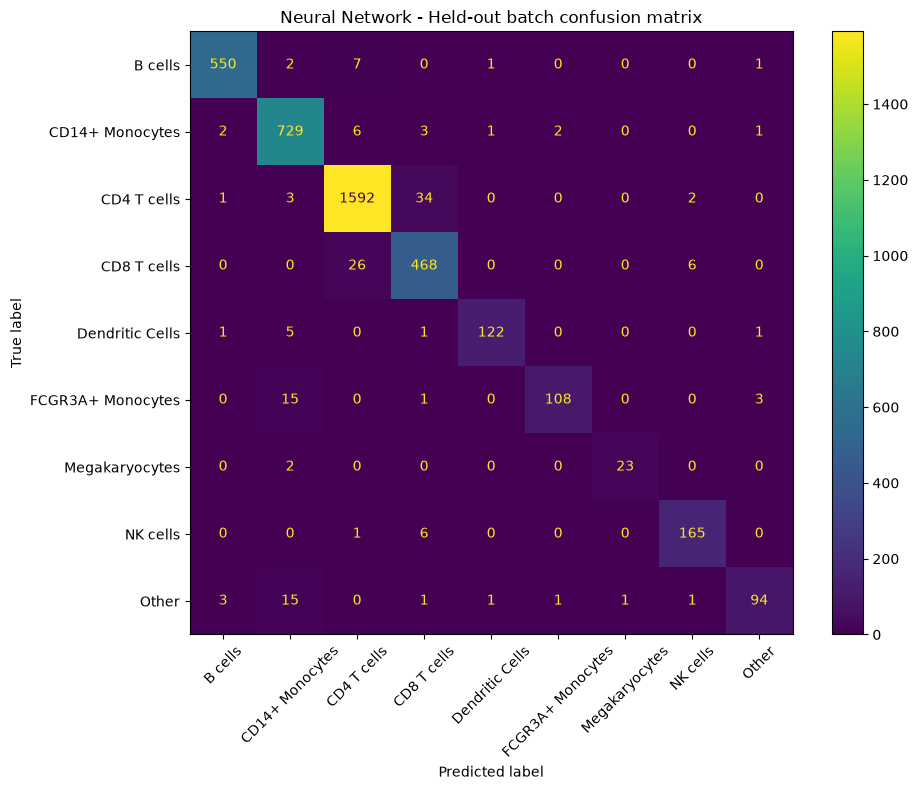

In [38]:
# NN confusion matrix
fig, ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    test_targets_nn,
    test_predictions_nn,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Neural Network - Held-out batch confusion matrix")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "nn_heldout_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# comparison table
comparison_df=pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Neural Network"
    ],
    "Validation Macro F1":[
        val_macro_f1,
        best_val_f1
    ],
    "Held-out Accuracy":[
        test_accuracy,
        nn_test_accuracy
    ],
    "Held-out Macro F1":[
        test_macro_f1,
        nn_test_macro_f1
    ]
})

comparison_df.round(4)

,Model,Validation Macro F1,Held-out Accuracy,Held-out Macro F1
0,Logistic Regression,0.9182,0.9618,0.9391
1,Neural Network,0.9443,0.9608,0.9409


## Model comparison

- Both models achieved strong and very similar performance on the held-out experimental batch. Logistic Regression achieved slightly higher overall accuracy (96.2% versus 96.1%), while the neural network achieved slightly higher macro-F1 (0.941 versus 0.939).

- The very small difference between the models shows that the simpler linear baseline already captured much of the cell-type-associated signal in the selected gene-expression features. Although the neural network achieved a higher validation macro-F1, this advantage did not translate into a meaningful improvement on the held-out experimental batch.

- The neural network remains useful for investigating non-linear modelling and gene-level attribution, while the Logistic Regression results demonstrate the value of retaining a strong and comparatively simple baseline.

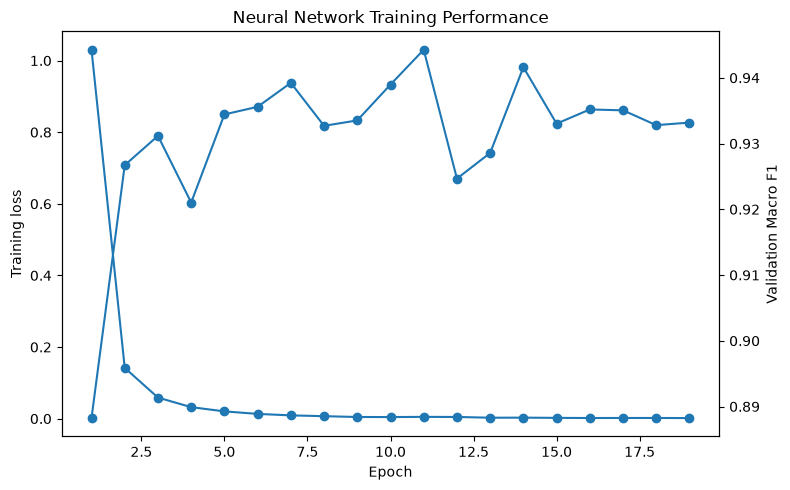

In [37]:
epochs = range(1, len(training_losses)+1)

fig, ax1= plt.subplots(figsize=(8,5))

ax1.plot(
    epochs,
    training_losses,
    marker="o",
    label="Training loss"
)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training loss")

ax2=ax1.twinx()

ax2.plot(
    epochs,
    validation_f1_scores,
    marker="o",
    label="Validation Macro F1"
)
ax2.set_ylabel("Validation Macro F1")

plt.title("Neural Network Training Performance")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "nn_training_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Model interpretation with Integrated Gradients
- Integrated Gradients (IG) is used to investigate which gene-expression features contributed most strongly to the Neural Network's (NN) cell type predictions.
- Attributions are calculated for correctly classified cells from the held-out experimental batch. A zero baseline is used in the standardised feature space, representing the training-set mean expression level for each selected gene.
- These attributions describe contributions to the model's predictions and should not be interpreted as equivalent to differential gene expression statistics.

In [29]:
# captum
from captum.attr import IntegratedGradients
ig= IntegratedGradients(model)

model.eval()
gene_ids=train.var_names.to_numpy()

print("Number of model features:", X_test_tensor.shape[1])
print("Number of gene IDs:", len(gene_ids))

print(train.var.columns)

gene_symbols=(
    train.var["gene_symbols"]
    .fillna(train.var_names.to_series())
    .astype(str)
    .to_numpy()
)

print(gene_symbols[:10])

Number of model features: 1000
Number of gene IDs: 1000
Index(['gene_symbols', 'n_counts-0', 'n_counts-1', 'n_counts', 'n_cells',
       'highly_variable', 'means', 'dispersions', 'dispersions_norm'],
      dtype='object')
['ISG15' 'PLCH2' 'PANK4' 'C1orf174' 'FBXO2' 'PLOD1' 'TNFRSF1B' 'DHRS3'
 'EFHD2' 'CDA']


In [30]:
test_predictions_nn=np.asarray(test_predictions_nn)
test_targets_nn=np.asarray(test_targets_nn)

correct_mask=test_predictions_nn == test_targets_nn

print("Correctly classified cells:", correct_mask.sum())
print("Total test cells:", len(test_targets_nn))

Correctly classified cells: 3851
Total test cells: 4008


## Gene-level attribution
- IG attributions are calculated for up to 100 correctly classified cells from each cell-type in the held-out batch. Attributions are calculated relative to a zero baseline in the standardised feature space, corresponding approximately to mean training-set expression for each gene.
- Positive attributions indicate features that contributed toward the model's prediction of a given cell-type. Attributions reflect model behaviour and are not equivalent to differential gene-expression statistics.

In [31]:
# IG for correctly classified held-out cells

rng=np.random.default_rng(SEED)

attribution_results={}

for class_idx, class_name in enumerate(label_encoder.classes_):
    class_indices=np.where(
        (test_targets_nn == class_idx) &
        (test_predictions_nn == class_idx)
    )[0]
    n_samples=min(100, len(class_indices))

    selected_indices=rng.choice(
        class_indices,
        size=n_samples,
        replace=False
    )

    class_inputs=X_test_tensor[selected_indices]
    
    baseline=torch.zeros_like(class_inputs)
    
    attributions=ig.attribute(
        class_inputs,
        baselines=baseline,
        target=class_idx,
        n_steps=50,
        internal_batch_size=256
    )

    # avg gene attributions across selected cells
    mean_attribution=attributions.mean(dim=0).detach().cpu().numpy()
    attribution_results[class_name]=mean_attribution
    print(f"{class_name}: {n_samples} cells")

B cells: 100 cells
CD14+ Monocytes: 100 cells
CD4 T cells: 100 cells
CD8 T cells: 100 cells
Dendritic Cells: 100 cells
FCGR3A+ Monocytes: 100 cells
Megakaryocytes: 23 cells
NK cells: 100 cells
Other: 94 cells


In [32]:
# extract top genes
top_gene_tables={}

for class_name, mean_attribution in attribution_results.items():
    attribution_df=pd.DataFrame({
        "Gene": gene_symbols,
        "Attribution": mean_attribution
    })
    attribution_df=(
        attribution_df
        .sort_values("Attribution", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )
    top_gene_tables[class_name]=attribution_df

    print(f"\n{class_name}")
    display(attribution_df)


B cells


,Gene,Attribution
0,CD79A,0.484601
1,CD79B,0.462001
2,BANK1,0.381190
3,HLA-DOB,0.335802
4,VPREB3,0.274429
5,TSPAN13,0.264791
6,EAF2,0.262796
7,CD72,0.258653
8,CD74,0.239122
9,CD19,0.238393



CD14+ Monocytes


,Gene,Attribution
0,RPS27,0.380363
1,RPS29,0.291061
2,LTB,0.283765
3,RPS18,0.215815
4,LGALS2,0.208729
5,IL32,0.186967
6,CD3D,0.182915
7,CFD,0.180785
8,CLEC7A,0.177210
9,RPS12,0.170391



CD4 T cells


...

,Gene,Attribution
0,TUBB1,0.853007
1,PPBP,0.826237
2,GNG11,0.803490
3,PF4,0.790923
4,TMEM40,0.635239
5,LCN2,0.619987
6,CLDN5,0.555681
7,HIST1H2AC,0.503669
8,TSC22D1,0.501092
9,GP9,0.486340



NK cells


,Gene,Attribution
0,KLRF1,0.817975
1,IL2RB,0.468817
2,RHOC,0.408214
3,MATK,0.406483
4,PRF1,0.375925
5,GZMB,0.338435
6,KLRB1,0.287877
7,AKR1C3,0.273786
8,PRSS23,0.272802
9,FCER1G,0.268436



Other


,Gene,Attribution
0,SCT,0.614424
1,LILRA4,0.604109
2,PTPRS,0.577068
3,IL3RA,0.541675
4,DNASE1L3,0.379571
5,SERPINF1,0.331245
6,TSPAN13,0.309372
7,SPIB,0.295279
8,SMPD3,0.289735
9,GZMB,0.277883


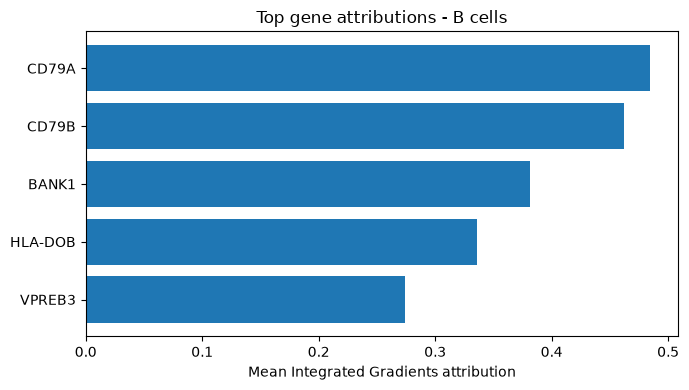

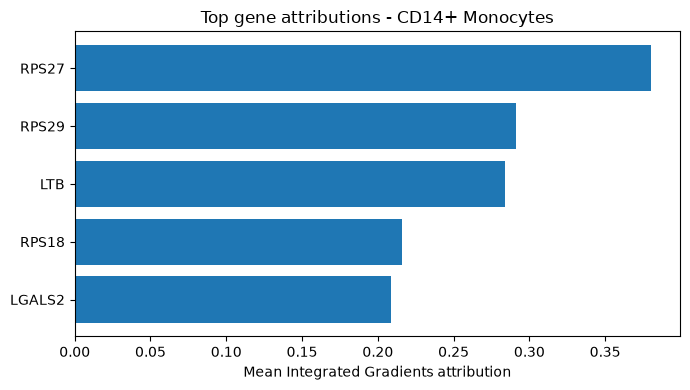

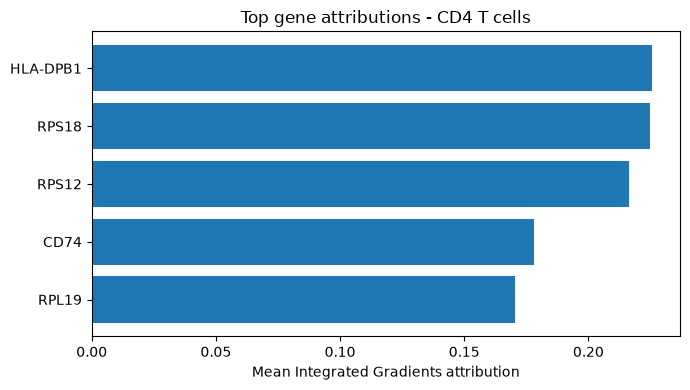

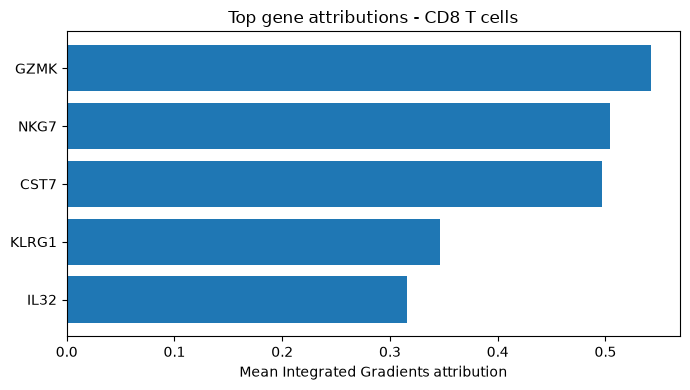

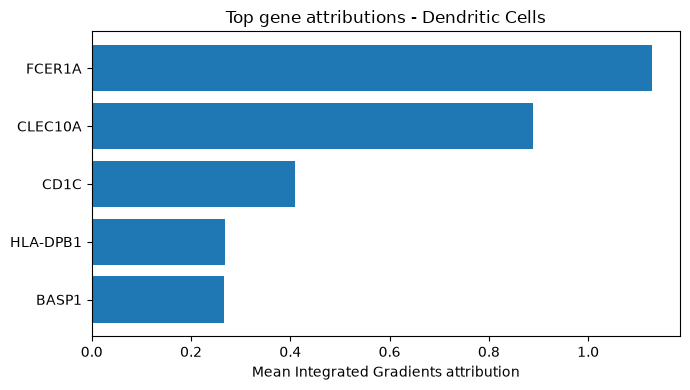

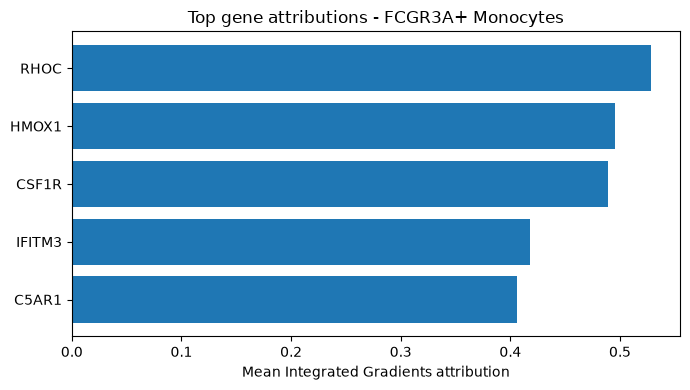

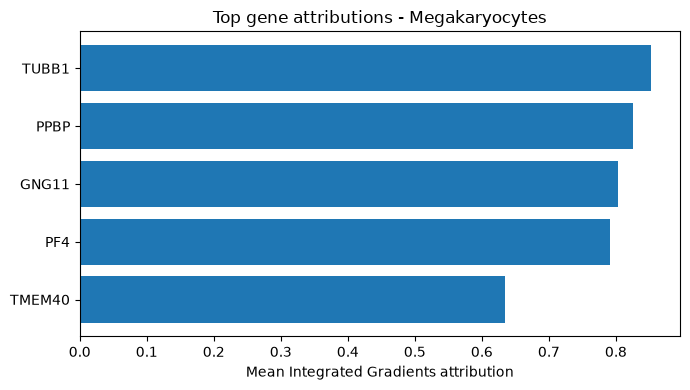

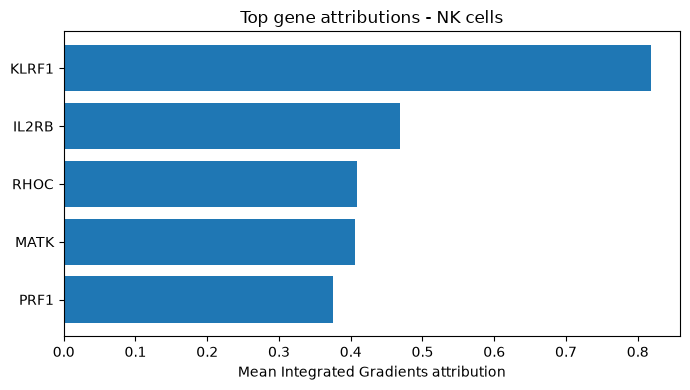

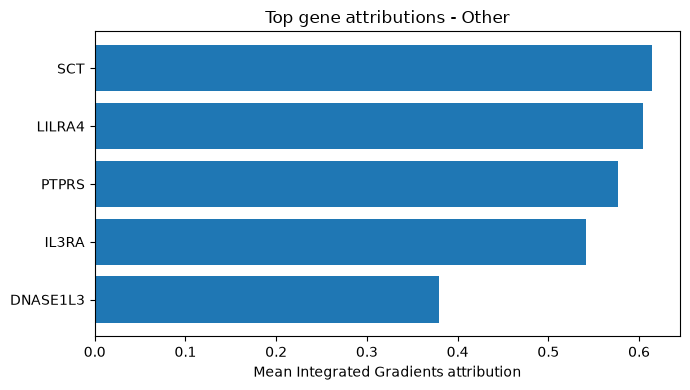

,Cell_Type,Gene,Attribution
0,B cells,CD79A,0.484601
1,B cells,CD79B,0.462001
2,B cells,BANK1,0.381190
3,B cells,HLA-DOB,0.335802
4,B cells,VPREB3,0.274429
...,...,...,...
85,Other,SERPINF1,0.331245
86,Other,TSPAN13,0.309372
87,Other,SPIB,0.295279
88,Other,SMPD3,0.289735


,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic Cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells,Other
1,CD79A,RPS27,HLA-DPB1,GZMK,FCER1A,RHOC,TUBB1,KLRF1,SCT
2,CD79B,RPS29,RPS18,NKG7,CLEC10A,HMOX1,PPBP,IL2RB,LILRA4
3,BANK1,LTB,RPS12,CST7,CD1C,CSF1R,GNG11,RHOC,PTPRS
4,HLA-DOB,RPS18,CD74,KLRG1,HLA-DPB1,IFITM3,PF4,MATK,IL3RA
5,VPREB3,LGALS2,RPL19,IL32,BASP1,C5AR1,TMEM40,PRF1,DNASE1L3
6,TSPAN13,IL32,CD3D,CTSW,ALDH2,CTSL,LCN2,GZMB,SERPINF1
7,EAF2,CD3D,RPL11,GZMH,CD33,HCK,CLDN5,KLRB1,TSPAN13
8,CD72,CFD,RPS29,CD8A,CD74,MAFB,HIST1H2AC,AKR1C3,SPIB
9,CD74,CLEC7A,MAL,CD3D,HLA-DMB,C1QA,TSC22D1,PRSS23,SMPD3
10,CD19,RPS12,HLA-DMB,DUSP2,HLA-DMA,FCER1G,GP9,FCER1G,GZMB


In [40]:
# plot these attributions
for class_name, attribution_df in top_gene_tables.items():

    top5=attribution_df.head(5).sort_values(
        "Attribution",
        ascending=True
    )
    plt.figure(figsize=(7,4))
    plt.barh(
        top5["Gene"],
        top5["Attribution"]
    )
    plt.xlabel("Mean Integrated Gradients attribution")
    plt.title(f"Top gene attributions - {class_name}")
    plt.tight_layout()
    
    if class_name == "Dendritic Cells":
        plt.savefig(
            FIGURES_DIR / "ig_dendritic_cells.png",
            dpi=300,
            bbox_inches="tight"
        )
    
    plt.show()

# combine top gene attributions into one table
top_genes_summary=pd.concat(
    [
        df.assign(Cell_Type=class_name)
        for class_name, df in top_gene_tables.items()
    ],
    ignore_index=True
)
top_genes_summary=top_genes_summary[
    ["Cell_Type", "Gene", "Attribution"]
    ]
display(top_genes_summary)

top_genes_wide=pd.DataFrame({
    class_name:df["Gene"].tolist()
    for class_name, df in top_gene_tables.items()
})
top_genes_wide.index=range(1,11)
display(top_genes_wide)

## Biological interpretation of gene attributions
- Integrated Gradients identified biologically plausible gene-level contributions for several cell populations. B-cell predictions were strongly associated with genes including CD79A, CD79B, BANK1 and CD19.
- The CD8 T-cell attribution profile contained cytotoxic and T-cell-associated genes including GZMK, NKG7, CST7, CTSW, GZMH and CD8A. Similarly, NK-cell predictions were influenced by genes including KLRF1, IL2RB, PRF1 and GZMB. Megakaryocyte predictions showed a clear platelet-associated profile including TUBB1, PPBP, PF4 and GP9.
- Dendritic-cell predictions showed a particularly coherent attribution profile, including FCER1A, CLEC10A, CD1C and antigen-presentation-associated genes. The FCGR3A+ monocyte profile included myeloid-associated genes such as CSF1R, HMOX1, C5AR1, HCK and MAFB. In contrast, the CD14+ monocyte and CD4 T-cell attribution profiles contained several ribosomal or less cell-type-specific features, illustrating that attribution patterns were not equally specific for all classes.
- The heterogeneous "Other" category included LILRA4, IL3RA, SPIB, DNASE1L3 and GZMB, suggesting that some cells within this group may have a plasmacytoid-dendritic-cell-like expression profile.
- Overall, the attribution results suggest that the neural network learned biologically meaningful expression patterns for several populations. However, Integrated Gradients measures contributions to model predictions and should not be interpreted as differential gene expression, causal relationships or definitive biological markers.

## Limitations
Several limitations should be considered:
- The analysis uses a single PBMC dataset containing two experimental batches. Holding one batch out provides a useful test of cross-batch generalisation, but performance may differ on independent datasets generated using different samples, laboratories or sequencing protocols.
- The neural network architecture was intentionally simple and no extensive hyperparameter optimisation was performed. The aim was to compare a straightforward NN with a strong classical baseline rather than to maximise predictive performance.
- The dataset contains pre-assigned cell-type labels, meaning model performance depends on the quality and biological resolution of those labels. The "Other" category is difficult to interpret.
- Integrated Gradients attributions are dependent on the trained model and the chosen baseline. They describe which input features contributed to model predictions and should not be interpreted as differential expression, casual relationship or definitive biological markers.

## Conclusion
- This project investigated whether cell types could be classified from single-cell RNA-seq expression profiles while retaining interpretable gene-level information.
- Both Logistic Regression and a feed-forward neural network generalised strongly to a held-out experimental batch. Logistic Regression achieved 96.2% accuracy and a macro-F1 score of 0.939, while the neural network achieved 96.1% accuracy and a macro-F1 score of 0.941. The near-equivalent held-out performance shows that the simpler linear model already captured much of the predictive signal, while the neural network provided only a marginal improvement in class-balanced performance.
- Integrated Gradients identified biologically plausible contributions for several populations, including B-cell, cytotoxic T-cell, dendritic-cell, NK-cell and megakaryocyte-associated genes. This demonstrates how predictive modelling and model interpretation can be combined to investigate both classification performance and the biological features influencing model decisions.
- Overall, the project demonstrates a reproducible workflow combining batch-aware experimental design, classical machine learning, neural-network classification and interpretable deep learning for single-cell RNA-seq data.